# Experiment 02 — Myocardial Paired Supervised Baseline

Train direct 2D U-Net models to predict paired T2 and C0 (static bSSFP) images from LGE. This is the supervised image-to-image baseline and follows Experiment 01, the retained diffusion study. Outputs are stored under this experiment's `results/` directory.

## Workflow and interpretation

The notebook discovers paired subjects from `Myo_train/MyoPS_train` and `Myo_val/MyoPS_val`, reviews validation image geometry and multi-case overlays, then trains one U-Net per requested target modality. It records training curves and evaluates held-out subjects using MAE, SSIM, and PSNR against both an LGE-copy and a training-target-mean baseline.

The existing project pipeline normalizes each volume to `[-1, 1]`, resamples a target onto the LGE voxel grid when geometry differs, and resizes 2D slices to the selected model resolution. Matching voxel geometry does **not** prove anatomical registration. These outputs are research diagnostics, not clinically validated images or quantitative T2 maps.

In [1]:
import csv
import importlib
import os
import sys
from pathlib import Path

os.environ.setdefault("TF_USE_LEGACY_KERAS", "1")

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from IPython.display import Image, Markdown, display

project_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_DIR = next(
    (path.resolve() for path in project_candidates
     if (path / "paired_supervised_baseline.py").is_file()
     and (path / "myocardial_data.py").is_file()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Could not find paired_supervised_baseline.py and myocardial_data.py "
        "in the current directory or its parents. Open this notebook from "
        "the myocardial-gdm project, or add that project directory to sys.path."
    )
sys.path.insert(0, str(PROJECT_DIR))

data_root_candidates = [Path.cwd(), *Path.cwd().parents, PROJECT_DIR, PROJECT_DIR.parent]
DATA_ROOT = next(
    (path.resolve() for path in data_root_candidates
     if (path / "Myo_train" / "MyoPS_train").is_dir()
     and (path / "Myo_val" / "MyoPS_val").is_dir()),
    None,
)
if DATA_ROOT is None:
    raise FileNotFoundError(
        "Could not find Myo_train/MyoPS_train and Myo_val/MyoPS_val. "
        "Set DATA_ROOT explicitly in this cell to their common parent directory."
    )

import myocardial_data
importlib.reload(myocardial_data)
import paired_supervised_baseline
importlib.reload(paired_supervised_baseline)

from myocardial_data import find_paired_cases, paired_case_counts
from paired_supervised_baseline import audit_alignment, train_and_evaluate_modality

print(f"Project: {PROJECT_DIR}")
print(f"Data root: {DATA_ROOT}")
print(f"Python: {sys.executable}")
print(f"TensorFlow: {tf.__version__}")
print(f"GPU devices: {tf.config.list_physical_devices('GPU')}")

I0000 00:00:1792094377.636796  114409 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792094377.676241  114409 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792094378.639107  114409 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Project: /home/molham/COT6931 Research/myocardial-gdm
Data root: /home/molham/COT6931 Research
Python: /home/molham/miniconda3/envs/myocardial-gdm/bin/python
TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Experiment settings

The defaults match the completed baseline run. Change `MODALITIES` to train only one target, or adjust the resolution, batch size, and epoch limit for an experiment. A separate best-validation checkpoint and CSV history are written for each modality.

In [2]:
IMAGE_SIZE = 96
BATCH_SIZE = 8
MAX_EPOCHS = 40
MODALITIES = ["T2", "C0"]  # C0 is the static bSSFP target in this dataset.
CASES_PER_MODALITY_IN_ALIGNMENT_REVIEW = 8
OUTPUT_DIR = PROJECT_DIR / "experiments" / "02_supervised" / "results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if IMAGE_SIZE <= 0 or IMAGE_SIZE % 8:
    raise ValueError("IMAGE_SIZE must be a positive multiple of 8")
if BATCH_SIZE <= 0 or MAX_EPOCHS <= 0:
    raise ValueError("BATCH_SIZE and MAX_EPOCHS must be positive")
if not MODALITIES or not set(MODALITIES).issubset({"T2", "C0"}):
    raise ValueError("MODALITIES must contain T2, C0, or both")

print(f"Image size: {IMAGE_SIZE} x {IMAGE_SIZE}")
print(f"Batch size: {BATCH_SIZE}; maximum epochs: {MAX_EPOCHS}")
print(f"Targets: {MODALITIES}")
print(f"Results directory: {OUTPUT_DIR}")

Image size: 96 x 96
Batch size: 8; maximum epochs: 40
Targets: ['T2', 'C0']
Results directory: /home/molham/COT6931 Research/myocardial-gdm/paired_baseline_results


## Paired case inventory

Only subjects with an LGE and the requested target modality in the same split are included. Validation subjects remain separate from training subjects.

In [3]:
TRAIN_PAIRS = find_paired_cases(DATA_ROOT / "Myo_train" / "MyoPS_train")
VALID_PAIRS = find_paired_cases(DATA_ROOT / "Myo_val" / "MyoPS_val")

print("Training paired cases:", dict(paired_case_counts(TRAIN_PAIRS)))
print("Validation paired cases:", dict(paired_case_counts(VALID_PAIRS)))
print(f"Training paired records: {len(TRAIN_PAIRS)}")
print(f"Validation paired records: {len(VALID_PAIRS)}")

Training paired cases: {'C0': 104, 'T2': 80}
Validation paired cases: {'C0': 15, 'T2': 15}
Training paired records: 184
Validation paired records: 30


## Validation alignment and geometry review

The panels show the same central slice index after the target is resampled to the LGE grid where needed. Red/green overlays make spatial differences visible; inspect the images and metadata rather than treating a matching affine as proof of registration.

Alignment metadata records: 16
Geometry table: /home/molham/COT6931 Research/myocardial-gdm/paired_baseline_results/alignment_metadata.csv
Validation LGE/T2 alignment review


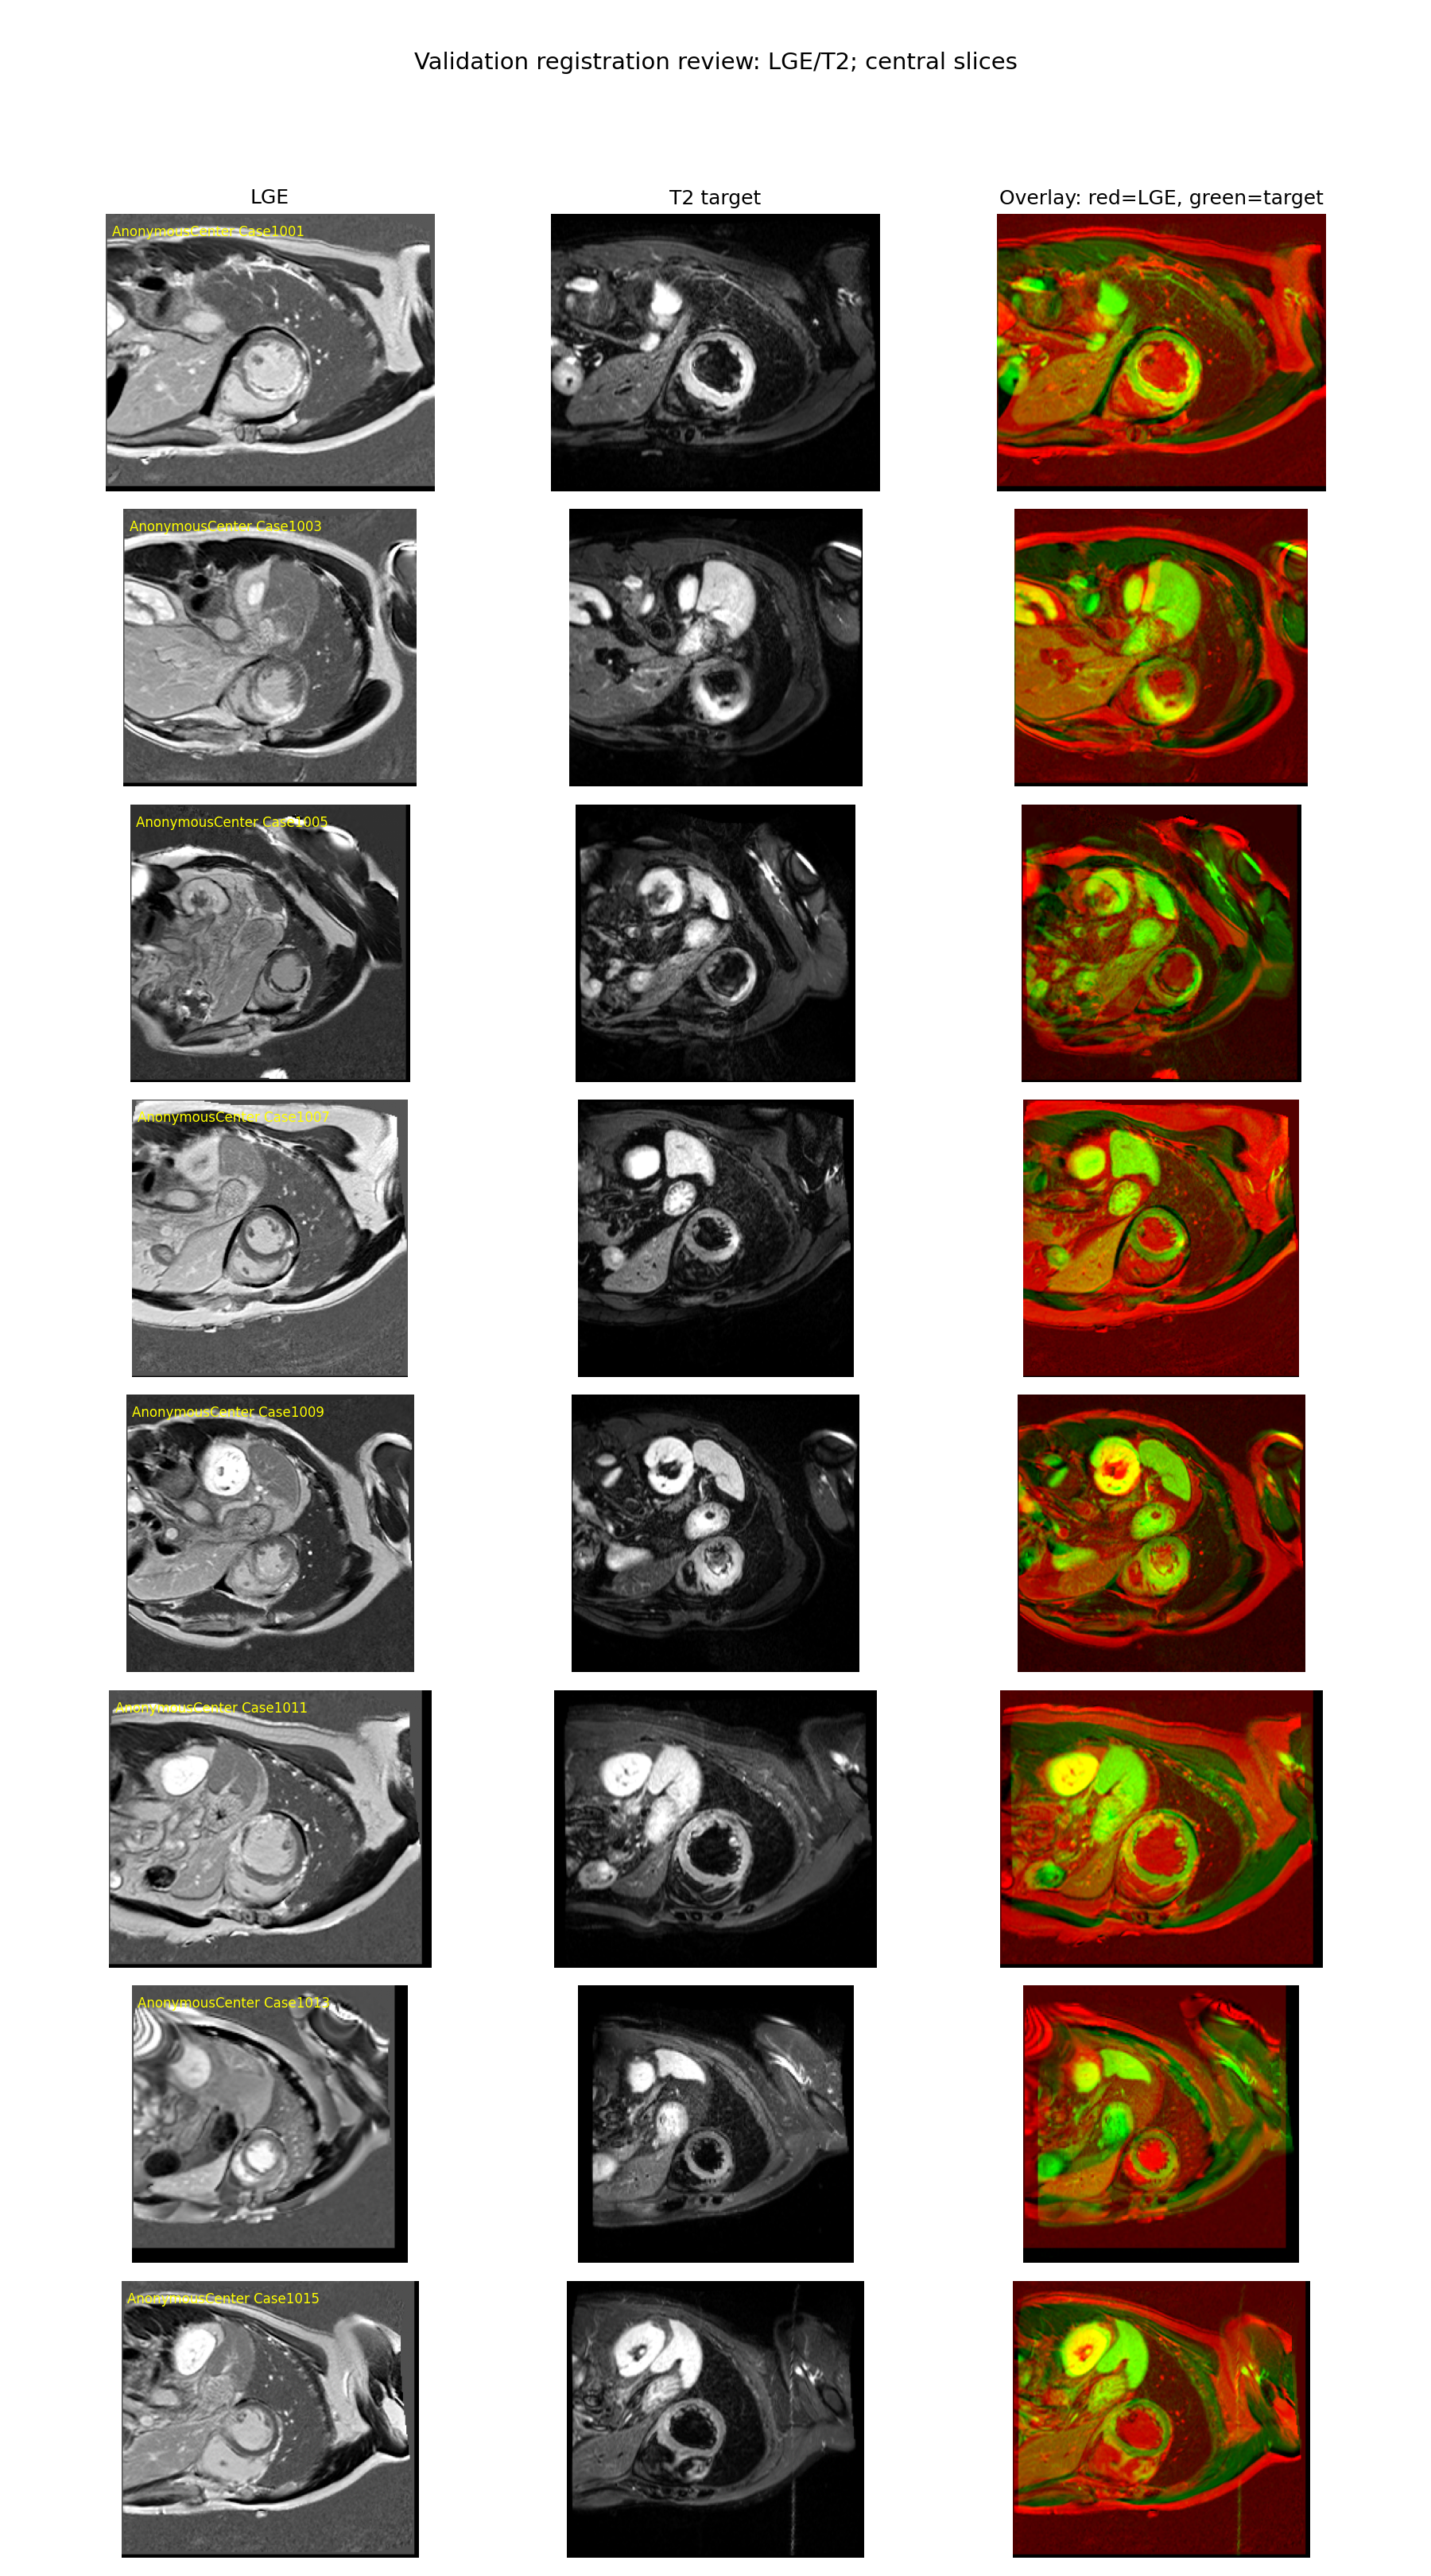

Validation LGE/C0 alignment review


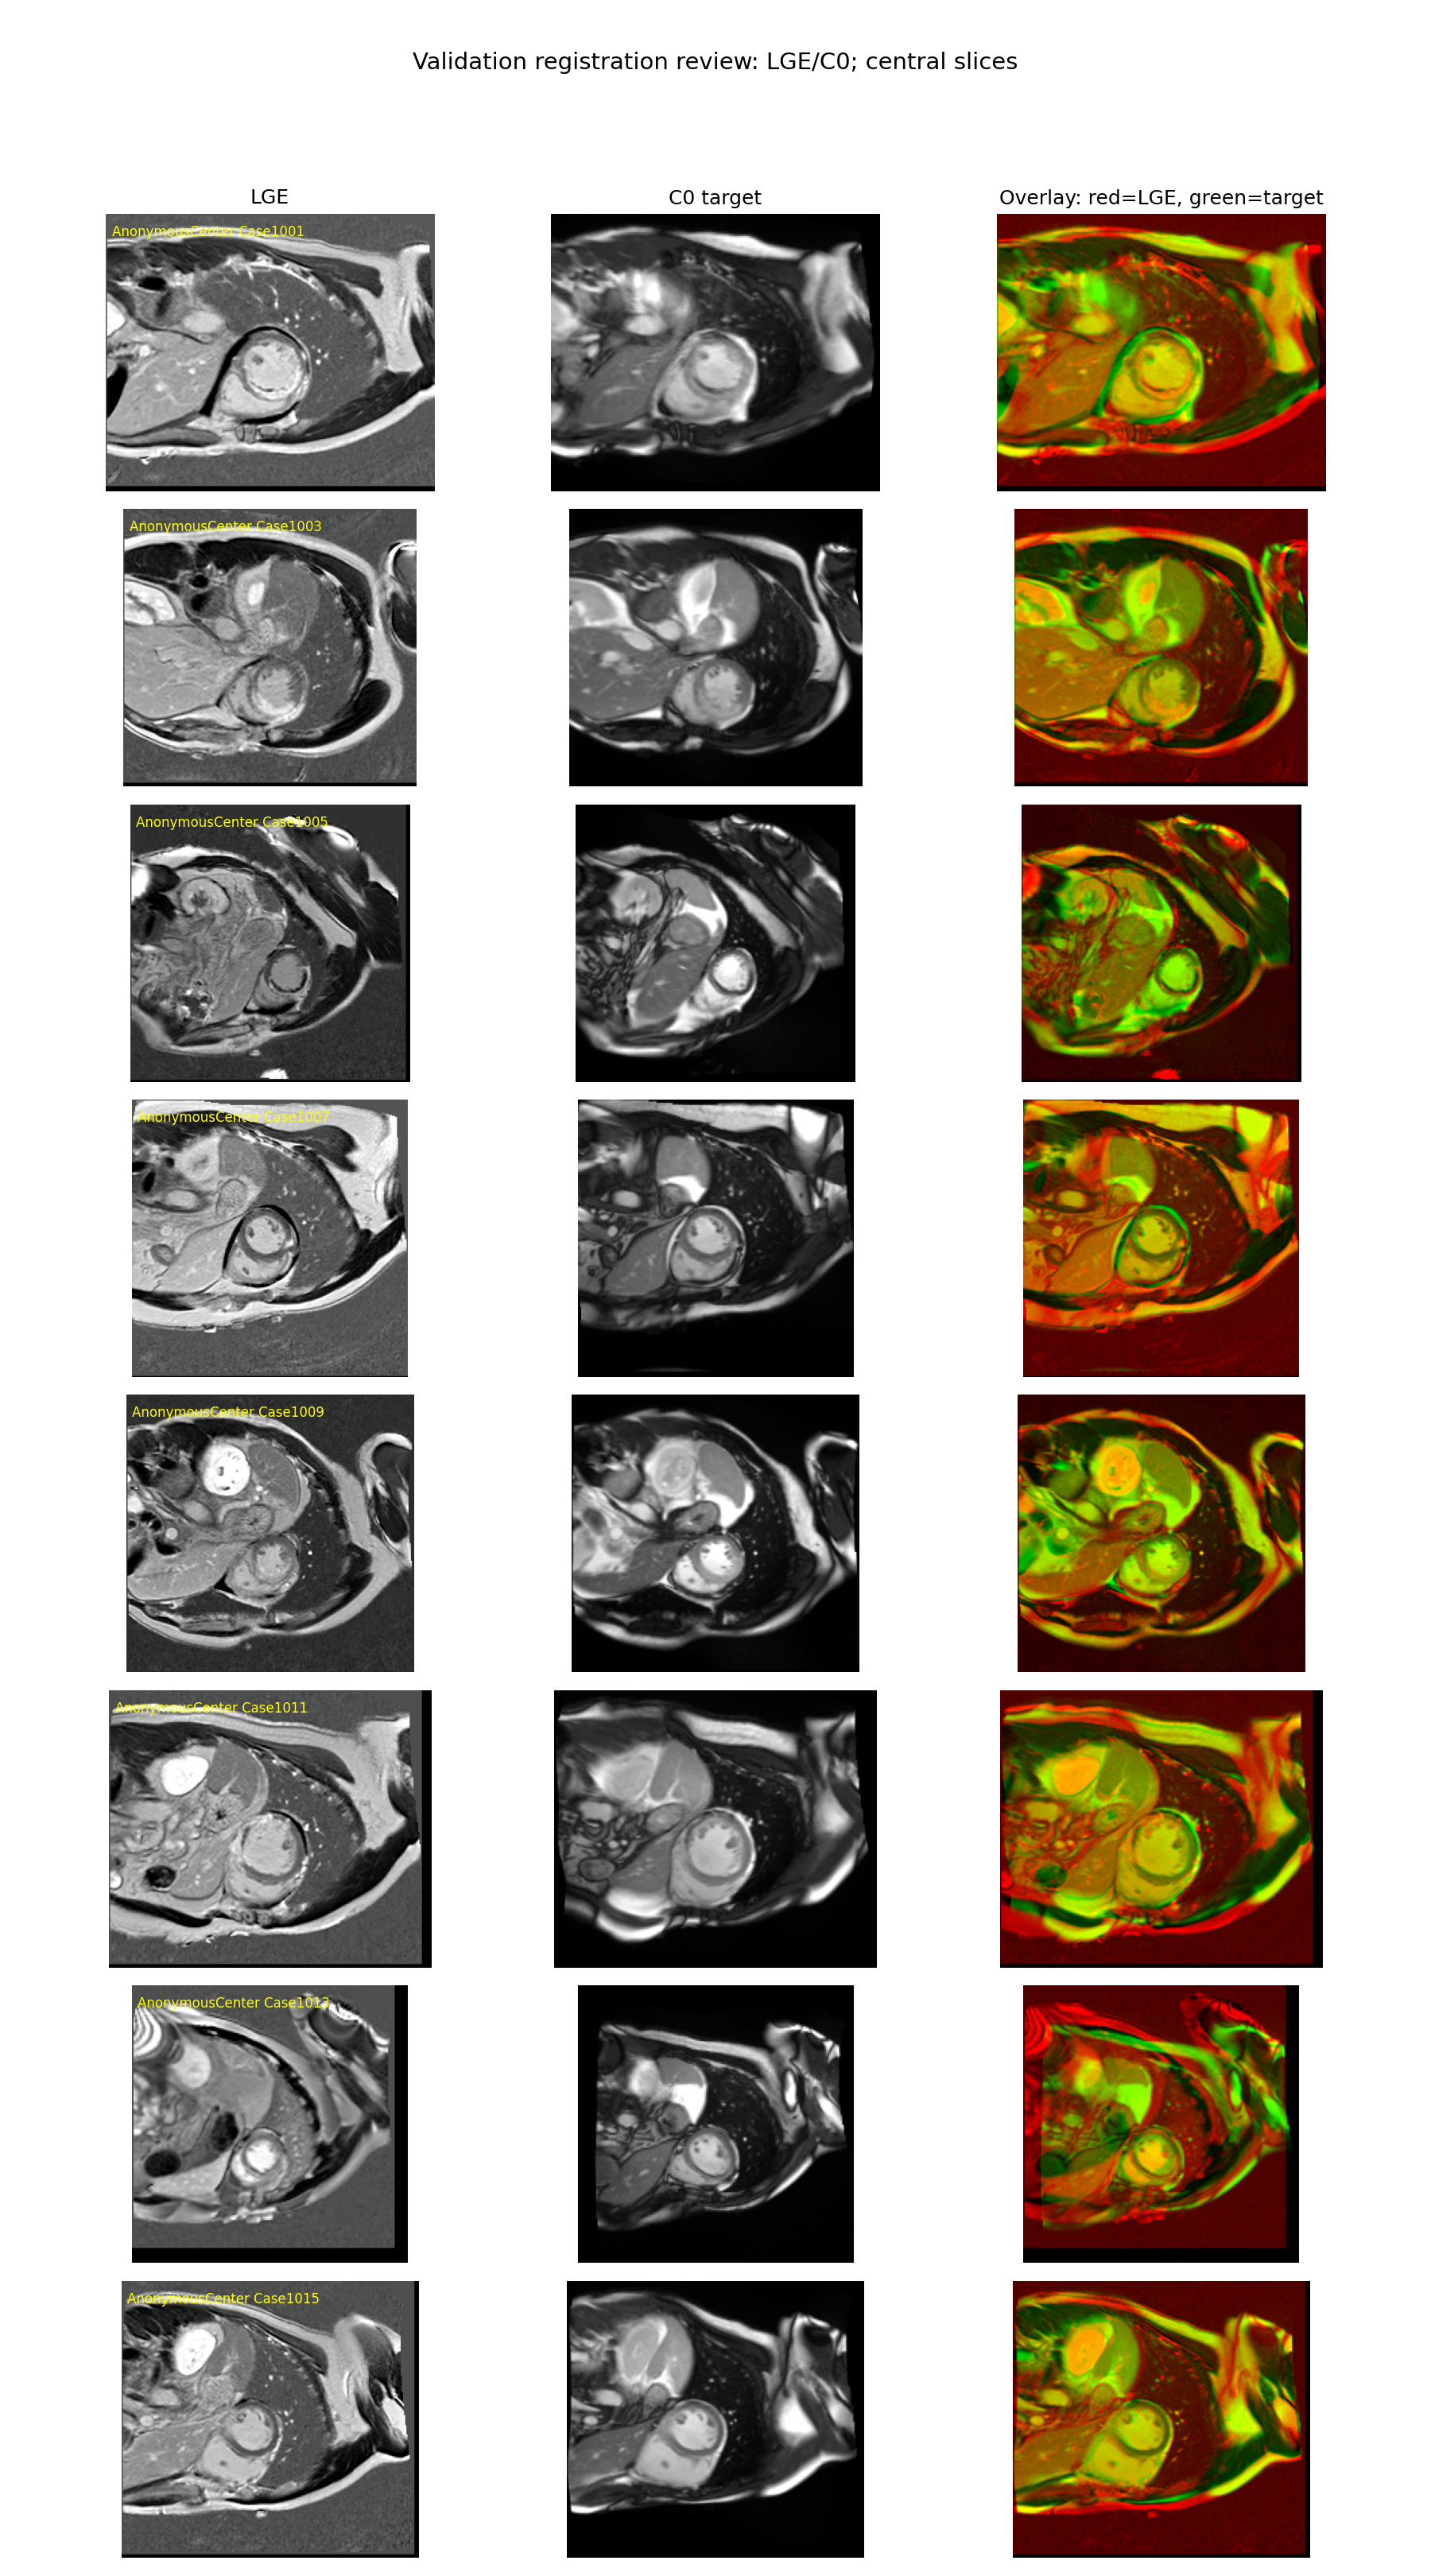

In [4]:
alignment_rows = audit_alignment(
    VALID_PAIRS,
    OUTPUT_DIR,
    cases_per_modality=CASES_PER_MODALITY_IN_ALIGNMENT_REVIEW,
)
print(f"Alignment metadata records: {len(alignment_rows)}")
print(f"Geometry table: {OUTPUT_DIR / 'alignment_metadata.csv'}")
for modality in ("T2", "C0"):
    panel_path = OUTPUT_DIR / f"alignment_{modality}.png"
    if panel_path.is_file():
        print(f"Validation LGE/{modality} alignment review")
        display(Image(filename=str(panel_path)))

## Train direct LGE-to-target U-Nets

Each modality gets an independent model. Training uses paired normalized 2D slices, Huber loss, Adam with gradient clipping, best-validation checkpointing, learning-rate reduction, and early stopping. This cell performs the full training run for the targets in `MODALITIES`.

In [ ]:
importlib.reload(paired_supervised_baseline)
train_and_evaluate_modality = paired_supervised_baseline.train_and_evaluate_modality

all_validation_metrics = []
for seed, modality in enumerate(MODALITIES, start=42):
    print(f"\nTraining LGE-to-{modality} supervised U-Net")
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    modality_metrics = train_and_evaluate_modality(
        TRAIN_PAIRS,
        VALID_PAIRS,
        modality,
        OUTPUT_DIR,
        image_size=IMAGE_SIZE,
        batch_size=BATCH_SIZE,
        epochs=MAX_EPOCHS,
    )
    all_validation_metrics.extend(modality_metrics)
    print(f"Finished {modality}: evaluated {len(modality_metrics)} validation subjects")

if not all_validation_metrics:
    raise RuntimeError("No validation metrics were produced; check paired-case availability")

per_case_path = OUTPUT_DIR / "validation_metrics_by_case.csv"
with per_case_path.open("w", newline="", encoding="utf-8") as output_file:
    writer = csv.DictWriter(output_file, fieldnames=list(all_validation_metrics[0]))
    writer.writeheader()
    writer.writerows(all_validation_metrics)
print(f"Saved per-case metrics to {per_case_path}")

### Training and validation curves

The CSV histories are retained so plots can be regenerated without retraining.

In [ ]:
for modality in MODALITIES:
    history_path = OUTPUT_DIR / f"lge_to_{modality}_history.csv"
    if not history_path.is_file():
        raise FileNotFoundError(f"No training history found for {modality}: {history_path}")
    with history_path.open(newline="", encoding="utf-8") as history_file:
        history_rows = list(csv.DictReader(history_file))
    if not history_rows:
        raise ValueError(f"Training history is empty: {history_path}")
    epochs = [int(row["epoch"]) + 1 for row in history_rows]
    train_loss = [float(row["loss"]) for row in history_rows]
    valid_loss = [float(row["val_loss"]) for row in history_rows]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, train_loss, label="Training")
    axes[0].plot(epochs, valid_loss, label="Validation")
    axes[0].set(title=f"LGE-to-{modality} Huber loss", xlabel="Epoch", ylabel="Loss")
    axes[0].grid(True)
    axes[0].legend()
    if "mae" in history_rows[0] and "val_mae" in history_rows[0]:
        axes[1].plot(epochs, [float(row["mae"]) for row in history_rows], label="Training")
        axes[1].plot(epochs, [float(row["val_mae"]) for row in history_rows], label="Validation")
        axes[1].set(title=f"LGE-to-{modality} MAE", xlabel="Epoch", ylabel="MAE")
        axes[1].grid(True)
        axes[1].legend()
    else:
        axes[1].set_visible(False)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"training_{modality}.png", dpi=150)
    plt.show()
    plt.close(fig)

## Held-out validation metrics

Scores are computed per subject and then averaged equally by subject. Lower MAE and higher SSIM/PSNR indicate greater image similarity, but these metrics do not establish clinical usefulness.

In [ ]:
metric_columns = [
    "unet_mae", "unet_ssim", "unet_psnr",
    "lge_copy_mae", "lge_copy_ssim", "lge_copy_psnr",
    "training_mean_mae", "training_mean_ssim", "training_mean_psnr",
]
summary_rows = []
for modality in MODALITIES:
    modality_rows = [row for row in all_validation_metrics if row["modality"] == modality]
    if not modality_rows:
        continue
    summary_row = {"modality": modality, "validation_cases": len(modality_rows)}
    summary_row.update({
        column: float(np.mean([float(row[column]) for row in modality_rows]))
        for column in metric_columns
    })
    summary_rows.append(summary_row)

summary_path = OUTPUT_DIR / "validation_metrics_summary.csv"
with summary_path.open("w", newline="", encoding="utf-8") as summary_file:
    writer = csv.DictWriter(summary_file, fieldnames=list(summary_rows[0]))
    writer.writeheader()
    writer.writerows(summary_rows)
print("Equal-subject mean validation metrics:")
for row in summary_rows:
    print(
        f"{row['modality']} (n={row['validation_cases']}): "
        f"U-Net MAE={row['unet_mae']:.4f}, SSIM={row['unet_ssim']:.4f}, PSNR={row['unet_psnr']:.2f} dB; "
        f"LGE-copy MAE={row['lge_copy_mae']:.4f}; "
        f"training-mean MAE={row['training_mean_mae']:.4f}"
    )
print(f"Saved summary to {summary_path}")
display(Markdown("**Per-subject validation scores are saved in:** `validation_metrics_by_case.csv`"))
for row in sorted(all_validation_metrics, key=lambda item: (item["modality"], item["center"], item["case_id"])):
    print(
        f"{row['modality']} {row['center']} {row['case_id']}: "
        f"U-Net MAE={row['unet_mae']:.4f}, SSIM={row['unet_ssim']:.4f}; "
        f"training-mean MAE={row['training_mean_mae']:.4f}"
    )

## Inspect validation predictions

Compare LGE input, reference target, and direct U-Net output for multiple held-out subjects. Predictions are generated at model resolution and resized to the original LGE in-plane dimensions for display.

In [ ]:
for modality in MODALITIES:
    prediction_path = OUTPUT_DIR / f"predictions_{modality}.png"
    if not prediction_path.is_file():
        raise FileNotFoundError(
            f"No validation prediction panel found for {modality}: {prediction_path}. "
            "Run the training cell for this modality first."
        )
    print(f"LGE-to-{modality} held-out predictions")
    display(Image(filename=str(prediction_path)))

## Saved outputs and limitations

The `experiments/02_supervised/results/` folder contains per-modality best checkpoints, CSV training histories, loss/MAE plots, validation prediction panels, alignment figures and geometry metadata, plus per-subject and summary validation metrics. Re-run the setup, configuration, inventory, and alignment cells as needed; rerun training only when you intend to overwrite the selected modality's checkpoint and history. Embedded notebook outputs may be from an earlier run; the saved result files are the organized record, and the training cell must be rerun to use the current helper code.

This is a small-data baseline intended to diagnose the paired mapping. Blurry predictions or modest metrics are not evidence of a successful clinical prediction system. Review image registration and multiple cases, and treat all outputs as experimental.